# Tutorial 5: Juntar tabelas (concat, merge e join)

**Autor:** Fabio Stein

Este tutorial continua os Tutoriais 1 a 4. No [Tutorial 4](tutorial_data_wrangling_parte4.ipynb) você resumiu uma tabela com `groupby`. Aqui você vai aprender a **juntar várias tabelas**: empilhar arquivos de meses diferentes (`concat`) e combinar tabelas que se relacionam por uma chave (`merge` e `join`).

**Como usar:** execute uma célula por vez (`Shift + Enter`), leia a explicação antes e olhe o resultado depois. Os quadros **📚 Teoria (opcional)** podem ser deixados para uma segunda leitura.

| Parte | Assunto |
|---|---|
| 0 | Preparar o ambiente |
| 1 | Criar as tabelas da clínica |
| 2 | `concat`: empilhar e colar tabelas |
| 3 | `merge`: combinar tabelas por uma chave |
| 4 | Cuidados com as chaves |
| 5 | Anti-join: quem ficou sem par? |
| 6 | `join` pelo índice e resumo das três ferramentas |
| 7 | Juntando tudo: três tabelas e um `groupby` |
| 8 | Checklist antes e depois de juntar |
| 9 | Exercícios |

## Parte 0: Preparar o ambiente

### 📚 Teoria (opcional): o modelo relacional
Em 1970, Edgar Codd [1] propôs guardar dados em **várias tabelas pequenas que se relacionam**, em vez de uma tabela gigante com tudo repetido. É assim que funcionam os bancos de dados até hoje [4].

- **Chave primária:** a coluna que identifica cada linha **de forma única** (o `id` do tutor, o código do animal). Não pode repetir nem ficar vazia.
- **Chave estrangeira:** uma coluna que **aponta** para a chave primária de outra tabela. O `tutor_id` na tabela de animais diz de quem é cada animal.
- **Por que separar?** O nome e a cidade do tutor ficam escritos **uma vez só**. Se ele mudar de cidade, você corrige num lugar só, sem risco de esquecer uma cópia.

Na hora de analisar, porém, precisamos **juntar** as tabelas de novo. É disso que trata este tutorial.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Tudo pronto! pandas", pd.__version__)

Tudo pronto! pandas 3.1.1


## Parte 1: Criar as tabelas da clínica

Vamos simular uma **clínica veterinária** com três cadastros:

| Tabela | Uma linha é... | Chave primária |
|---|---|---|
| `tutores` | uma pessoa dona de animais | `id` |
| `animais` | um animal atendido na clínica | `animal_id` |
| `consultas` | um atendimento (um arquivo por mês) | `consulta_id` |

As tabelas são pequenas de propósito, para você conseguir conferir cada resultado **com os olhos**. E, como sempre, há problemas escondidos de propósito.

In [2]:
tutores = pd.DataFrame({
    "id": [1, 2, 3, 4, 5, 6],
    "nome": ["Marina Costa", "Rafael Lima", "Helena Souza", "Otávio Reis", "Lúcia Prado", "Tiago Moura"],
    "cidade": ["Curitiba", "Curitiba", "Londrina", "Maringá", "Curitiba", "Londrina"],
})
tutores

,id,nome,cidade
0,1,Marina Costa,Curitiba
1,2,Rafael Lima,Curitiba
2,3,Helena Souza,Londrina
3,4,Otávio Reis,Maringá
4,5,Lúcia Prado,Curitiba
5,6,Tiago Moura,Londrina


In [3]:
animais = pd.DataFrame({
    "animal_id": ["A01", "A02", "A03", "A04", "A05", "A06", "A07", "A08"],
    "nome": ["Thor", "Mel", "Pipoca", "Luna", "Bidu", "Nina", "Fred", "Amora"],
    "especie": ["cão", "gato", "cão", "gato", "cão", "coelho", "cão", "gato"],
    "tutor_id": ["1", "1", "2", "3", "4 ", "5", "99", "5"],   # veio de outro sistema, como texto
})
animais

,animal_id,nome,especie,tutor_id
0,A01,Thor,cão,1
1,A02,Mel,gato,1
2,A03,Pipoca,cão,2
3,A04,Luna,gato,3
4,A05,Bidu,cão,4
5,A06,Nina,coelho,5
6,A07,Fred,cão,99
7,A08,Amora,gato,5


Repare em três detalhes da tabela `animais` (vamos voltar a eles na Parte 4):
- `tutor_id` está como **texto** (`"1"`), enquanto em `tutores` o `id` é **número** (`1`).
- O Bidu tem `tutor_id` igual a `"4 "`, **com um espaço** no fim.
- O Fred aponta para o tutor `99`, que **não existe**.

Agora os atendimentos. Cada mês veio num **arquivo separado**, como acontece quando um sistema exporta um relatório por mês:

In [4]:
jan = pd.DataFrame({
    "consulta_id": [101, 102, 103, 104, 105],
    "data": ["2026-01-08", "2026-01-12", "2026-01-15", "2026-01-22", "2026-01-29"],
    "animal_id": ["A01", "A04", "A02", "A05", "A01"],
    "servico": ["consulta", "vacina", "consulta", "banho", "exame"],
    "valor": [150.0, 90.0, 150.0, 60.0, 220.0],
})
fev = pd.DataFrame({
    "consulta_id": [201, 202, 203, 204],
    "data": ["2026-02-03", "2026-02-10", "2026-02-17", "2026-02-24"],
    "animal_id": ["A06", "A03", "A01", "A08"],
    "servico": ["consulta", "vacina", "vacina", "consulta"],
    "valor": [120.0, 90.0, 90.0, 150.0],
    "veterinario": ["Dra. Bia", "Dr. Caio", "Dra. Bia", "Dr. Caio"],   # coluna nova a partir de fevereiro
})
mar = pd.DataFrame({
    "consulta_id": [301, 302, 303, 304, 305],
    "data": ["2026-03-02", "2026-03-09", "2026-03-11", "2026-03-20", "2026-03-27"],
    "animal_id": ["A04", "A03 ", "A99", "A05", "A02"],   # "A03 " com espaço; "A99" não existe
    "servico": ["exame", "consulta", "consulta", "vacina", "banho"],
    "valor": [220.0, 150.0, 150.0, 90.0, 60.0],
    "veterinario": ["Dra. Bia", "Dr. Caio", "Dr. Caio", "Dra. Bia", "Dr. Caio"],
})

for nome_arquivo, tabela in [("consultas_2026_01.csv", jan), ("consultas_2026_02.csv", fev), ("consultas_2026_03.csv", mar)]:
    tabela.to_csv(nome_arquivo, index=False)
print("Arquivos mensais criados!")

Arquivos mensais criados!


## Parte 2: `concat`: empilhar e colar tabelas

`pd.concat` **gruda** tabelas, sem procurar nenhuma relação entre elas:
- **na vertical** (`axis=0`, o padrão): uma tabela **embaixo** da outra. Use quando as tabelas têm **as mesmas colunas** (meses, filiais, anos).
- **na horizontal** (`axis=1`): uma tabela **ao lado** da outra, alinhando pelo **índice**.

### 2.1 Empilhar os arquivos mensais

### 🔍 Passo a passo
1. Lemos os três arquivos numa lista (num caso real, poderiam ser dezenas).
2. `pd.concat(lista)` coloca um embaixo do outro.
3. Sem cuidado, o índice **se repete** (0, 1, 2... de novo em cada mês).

In [5]:
arquivos = ["consultas_2026_01.csv", "consultas_2026_02.csv", "consultas_2026_03.csv"]
meses = [pd.read_csv(arquivo) for arquivo in arquivos]

empilhado = pd.concat(meses)
print("Linhas:", len(empilhado))
print("Índice:", empilhado.index.tolist())

Linhas: 14
Índice: [0, 1, 2, 3, 4, 0, 1, 2, 3, 0, 1, 2, 3, 4]


### 2.2 `ignore_index`: renumerar as linhas
Índice repetido confunde: `empilhado.loc[0]` devolveria **três** linhas. Com `ignore_index=True`, o pandas renumera de 0 até o fim.

In [6]:
consultas = pd.concat(meses, ignore_index=True)
consultas

,consulta_id,data,animal_id,servico,valor,veterinario
0,101,2026-01-08,A01,consulta,150.0,NaN
1,102,2026-01-12,A04,vacina,90.0,NaN
2,103,2026-01-15,A02,consulta,150.0,NaN
3,104,2026-01-22,A05,banho,60.0,NaN
4,105,2026-01-29,A01,exame,220.0,NaN
5,201,2026-02-03,A06,consulta,120.0,Dra. Bia
6,202,2026-02-10,A03,vacina,90.0,Dr. Caio
7,203,2026-02-17,A01,vacina,90.0,Dra. Bia
8,204,2026-02-24,A08,consulta,150.0,Dr. Caio
9,301,2026-03-02,A04,exame,220.0,Dra. Bia


### 2.3 Colunas diferentes viram `NaN`
Janeiro não tinha a coluna `veterinario`. O `concat` **une as colunas** de todas as tabelas e preenche o que falta com `NaN`. Não é um erro: é a forma honesta de dizer "essa informação não existia em janeiro".

In [7]:
consultas["veterinario"].isna().groupby(consultas["data"].str[:7]).sum()

data
2026-01    5
2026-02    0
2026-03    0
Name: veterinario, dtype: int64

Se você quiser **só as colunas que existem em todos os arquivos**, use `join="inner"`:

In [8]:
pd.concat(meses, ignore_index=True, join="inner").columns.tolist()

['consulta_id', 'data', 'animal_id', 'servico', 'valor']

### 2.4 `keys`: lembrar de onde veio cada linha
Com `keys`, o pandas cria um índice de dois níveis com o nome de cada pedaço. Depois, `reset_index` transforma esse nível numa coluna comum.

In [9]:
com_origem = pd.concat(meses, keys=["jan", "fev", "mar"])
com_origem = com_origem.reset_index(level=0).rename(columns={"level_0": "mes"}).reset_index(drop=True)
com_origem[["mes", "consulta_id", "animal_id", "servico"]].head(7)

,mes,consulta_id,animal_id,servico
0,jan,101,A01,consulta
1,jan,102,A04,vacina
2,jan,103,A02,consulta
3,jan,104,A05,banho
4,jan,105,A01,exame
5,fev,201,A06,consulta
6,fev,202,A03,vacina


### 2.5 Na horizontal: o perigo do índice
Com `axis=1`, o `concat` **não olha o conteúdo**: ele cola as linhas que têm **o mesmo índice**. Veja o que acontece quando uma das tabelas foi filtrada antes:

In [10]:
de_curitiba = tutores[tutores["cidade"] == "Curitiba"]          # índices 0, 1 e 4
telefones = pd.DataFrame({"telefone": ["41 9111-0001", "41 9111-0002", "41 9111-0005"]})   # índices 0, 1 e 2

print("Índices de_curitiba:", de_curitiba.index.tolist())
print("Índices telefones:  ", telefones.index.tolist())
pd.concat([de_curitiba, telefones], axis=1)

Índices de_curitiba: [0, 1, 4]
Índices telefones:   [0, 1, 2]


,id,nome,cidade,telefone
0,1.0,Marina Costa,Curitiba,41 9111-0001
1,2.0,Rafael Lima,Curitiba,41 9111-0002
4,5.0,Lúcia Prado,Curitiba,NaN
2,NaN,NaN,NaN,41 9111-0005


Em vez de 3 linhas, saíram **4**, com buracos: a Lúcia (índice 4) ficou sem telefone e apareceu uma linha só com telefone (índice 2). Uma correção é renumerar antes com `reset_index(drop=True)`:

In [11]:
pd.concat([de_curitiba.reset_index(drop=True), telefones], axis=1)

,id,nome,cidade,telefone
0,1,Marina Costa,Curitiba,41 9111-0001
1,2,Rafael Lima,Curitiba,41 9111-0002
2,5,Lúcia Prado,Curitiba,41 9111-0005


Funciona, mas **só porque as duas tabelas estavam na mesma ordem**. Se alguém tivesse ordenado uma delas, os telefones iriam para as pessoas erradas **sem nenhum aviso**. Por isso a regra é: **para combinar informações de duas tabelas, use uma chave com `merge`**. Deixe o `concat` horizontal para tabelas que você **sabe** que estão alinhadas.

## Parte 3: `merge`: combinar tabelas por uma chave

O `merge` procura, para cada linha da tabela da **esquerda**, as linhas da tabela da **direita** com **o mesmo valor na chave**. A pergunta principal é: **o que fazer com quem não encontrou par?** O parâmetro `how` responde:

| `how` | Mantém | No SQL |
|---|---|---|
| `"inner"` (padrão) | só quem tem par dos **dois** lados | `INNER JOIN` |
| `"left"` | **todas** as linhas da esquerda | `LEFT JOIN` |
| `"right"` | **todas** as linhas da direita | `RIGHT JOIN` |
| `"outer"` | **todas** as linhas dos dois lados | `FULL OUTER JOIN` |

Onde não há par, as colunas do outro lado ficam com `NaN`.

Vamos juntar `consultas` (esquerda) com `animais` (direita) pela coluna `animal_id`. Para ver com clareza, usamos só algumas colunas.

In [12]:
c = consultas[["consulta_id", "animal_id", "servico"]]
a = animais[["animal_id", "nome", "especie"]]
print("consultas:", len(c), "linhas | animais:", len(a), "linhas")

consultas: 14 linhas | animais: 8 linhas


### 3.1 `inner`: só os pares

In [13]:
inner = pd.merge(c, a, on="animal_id", how="inner")
print("Linhas:", len(inner))
inner

Linhas: 12


,consulta_id,animal_id,servico,nome,especie
0,101,A01,consulta,Thor,cão
1,102,A04,vacina,Luna,gato
2,103,A02,consulta,Mel,gato
3,104,A05,banho,Bidu,cão
4,105,A01,exame,Thor,cão
5,201,A06,consulta,Nina,coelho
6,202,A03,vacina,Pipoca,cão
7,203,A01,vacina,Thor,cão
8,204,A08,consulta,Amora,gato
9,301,A04,exame,Luna,gato


Sumiram 2 consultas (a do `"A99"` e a do `"A03 "`) e também os animais que nunca vieram à clínica. Num `inner`, **o que não tem par desaparece em silêncio**.

### 3.2 `left`: todas as consultas

In [14]:
left = pd.merge(c, a, on="animal_id", how="left")
print("Linhas:", len(left))
left.tail(6)

Linhas: 14


,consulta_id,animal_id,servico,nome,especie
8,204,A08,consulta,Amora,gato
9,301,A04,exame,Luna,gato
10,302,A03,consulta,NaN,NaN
11,303,A99,consulta,NaN,NaN
12,304,A05,vacina,Bidu,cão
13,305,A02,banho,Mel,gato


### 3.3 `right`: todos os animais

In [15]:
right = pd.merge(c, a, on="animal_id", how="right")
print("Linhas:", len(right))
right[right["consulta_id"].isna()]

Linhas: 13


,consulta_id,animal_id,servico,nome,especie
11,NaN,A07,NaN,Fred,cão


O Fred (`A07`) nunca teve consulta registrada, então aparece com `consulta_id` e `servico` vazios.

### 3.4 `outer` com `indicator=True`
O `outer` mantém tudo. Com `indicator=True`, o pandas cria a coluna **`_merge`**, que conta de onde veio cada linha:
- `both`: encontrou par;
- `left_only`: só existe na esquerda;
- `right_only`: só existe na direita.

In [16]:
outer = pd.merge(c, a, on="animal_id", how="outer", indicator=True)
outer["_merge"].value_counts()

_merge
both          12
left_only      2
right_only     1
Name: count, dtype: int64

In [17]:
outer[outer["_merge"] != "both"]

,consulta_id,animal_id,servico,nome,especie,_merge
6,302.0,A03,consulta,NaN,NaN,left_only
12,NaN,A07,NaN,Fred,cão,right_only
14,303.0,A99,consulta,NaN,NaN,left_only


Essa contagem resume tudo o que os outros `how` fazem:

| `how` | Fórmula | Linhas |
|---|---|---|
| `inner` | `both` | 12 |
| `left` | `both` + `left_only` | 12 + 2 = 14 |
| `right` | `both` + `right_only` | 12 + 1 = 13 |
| `outer` | tudo | 12 + 2 + 1 = 15 |

**Dica:** use `indicator=True` sempre que estiver na dúvida. É o jeito mais rápido de descobrir o que não casou.

## Parte 4: Cuidados com as chaves

Quase todo problema de junção é um problema de **chave**: nome diferente, tipo diferente, espaço sobrando ou valor repetido.

### 4.1 Nomes diferentes: `left_on` e `right_on`
Em `animais` a chave se chama `tutor_id`; em `tutores`, se chama `id`. Usamos `left_on` e `right_on` para dizer qual coluna de cada lado.

Primeiro, uma tentativa ingênua:

In [18]:
try:
    pd.merge(animais, tutores, left_on="tutor_id", right_on="id")
except ValueError as erro:
    print("ERRO:", erro)

ERRO: You are trying to merge on str and int64 columns for key 'tutor_id'. If you wish to proceed you should use pd.concat


### 4.2 Tipos diferentes: texto × número
O erro diz que estamos comparando **texto** com **número**. Para o computador, `"1"` (texto) e `1` (número) são coisas diferentes. Veja os tipos:

In [19]:
print("animais.tutor_id:", animais["tutor_id"].dtype, animais["tutor_id"].tolist())
print("tutores.id:      ", tutores["id"].dtype)

animais.tutor_id: str ['1', '1', '2', '3', '4 ', '5', '99', '5']
tutores.id:       int64


### 🔍 Passo a passo da correção
1. `.str.strip()` tira o espaço do `"4 "` (se você converter sem isso, o `"4 "` pode dar erro ou virar `NaN`).
2. `pd.to_numeric(..., errors="coerce")` converte para número; o que não for número vira `NaN` e aparece na contagem.
3. Guardamos o resultado na própria coluna e conferimos.

In [20]:
animais["tutor_id"] = pd.to_numeric(animais["tutor_id"].str.strip(), errors="coerce")
print("Tipo agora:", animais["tutor_id"].dtype)
print("Falharam na conversão:", animais["tutor_id"].isna().sum())

Tipo agora: int64
Falharam na conversão: 0


### 4.3 Colunas com o mesmo nome: `suffixes`
As duas tabelas têm uma coluna `nome` (do animal e do tutor). O `merge` não pode ter duas colunas iguais, então acrescenta `_x` e `_y`. Com `suffixes`, escolhemos nomes que fazem sentido:

In [21]:
animais_tutores = pd.merge(animais, tutores, left_on="tutor_id", right_on="id",
                           how="left", suffixes=("_animal", "_tutor"))
animais_tutores

,animal_id,nome_animal,especie,tutor_id,id,nome_tutor,cidade
0,A01,Thor,cão,1,1.0,Marina Costa,Curitiba
1,A02,Mel,gato,1,1.0,Marina Costa,Curitiba
2,A03,Pipoca,cão,2,2.0,Rafael Lima,Curitiba
3,A04,Luna,gato,3,3.0,Helena Souza,Londrina
4,A05,Bidu,cão,4,4.0,Otávio Reis,Maringá
5,A06,Nina,coelho,5,5.0,Lúcia Prado,Curitiba
6,A07,Fred,cão,99,NaN,NaN,NaN
7,A08,Amora,gato,5,5.0,Lúcia Prado,Curitiba


Repare: o Fred (tutor 99) ficou com `nome_tutor` vazio, porque esse tutor não existe. E sobrou a coluna `id`, repetindo `tutor_id`; podemos apagá-la com `.drop(columns="id")`.

### 4.4 Espaço escondido na chave
Lembra das 2 consultas que sumiram no `inner` da Parte 3? Uma era o `"A03 "`. Na tela ele parece igual a `"A03"`, mas tem um espaço no fim. O `repr` mostra o texto com aspas e deixa o espaço visível:

In [22]:
print([repr(x) for x in consultas["animal_id"].unique()])
consultas["animal_id"] = consultas["animal_id"].str.strip()
print("Depois do strip:", sorted(consultas["animal_id"].unique()))

["'A01'", "'A04'", "'A02'", "'A05'", "'A06'", "'A03'", "'A08'", "'A03 '", "'A99'"]
Depois do strip: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A08', 'A99']


### 4.5 Chave composta: mais de uma coluna
Às vezes uma coluna só não identifica a linha. A tabela de preços abaixo depende da **espécie e do serviço ao mesmo tempo**: a vacina de um cão custa diferente da vacina de um gato. Passamos uma **lista** em `on`.

In [23]:
precos = pd.DataFrame({
    "especie": ["cão", "cão", "cão", "cão", "gato", "gato", "gato", "gato", "coelho"],
    "servico": ["consulta", "vacina", "banho", "exame", "consulta", "vacina", "banho", "exame", "consulta"],
    "preco_tabela": [150.0, 90.0, 60.0, 220.0, 150.0, 90.0, 60.0, 220.0, 120.0],
})

com_especie = pd.merge(consultas, animais[["animal_id", "especie"]], on="animal_id", how="left")
conferencia = pd.merge(com_especie, precos, on=["especie", "servico"], how="left")
conferencia["diferenca"] = conferencia["valor"] - conferencia["preco_tabela"]
conferencia[["consulta_id", "animal_id", "especie", "servico", "valor", "preco_tabela", "diferenca"]]

,consulta_id,animal_id,especie,servico,valor,preco_tabela,diferenca
0,101,A01,cão,consulta,150.0,150.0,0.0
1,102,A04,gato,vacina,90.0,90.0,0.0
2,103,A02,gato,consulta,150.0,150.0,0.0
3,104,A05,cão,banho,60.0,60.0,0.0
4,105,A01,cão,exame,220.0,220.0,0.0
5,201,A06,coelho,consulta,120.0,120.0,0.0
6,202,A03,cão,vacina,90.0,90.0,0.0
7,203,A01,cão,vacina,90.0,90.0,0.0
8,204,A08,gato,consulta,150.0,150.0,0.0
9,301,A04,gato,exame,220.0,220.0,0.0


Todos os valores cobrados batem com a tabela (`diferenca` = 0). A única linha sem preço de tabela é a consulta do `A99`: sem animal cadastrado, não sabemos a espécie.

### 4.6 Chave repetida multiplica linhas
Imagine que a Marina foi **cadastrada duas vezes** por engano:

In [24]:
tutores_dup = pd.concat([tutores, tutores.iloc[[0]]], ignore_index=True)
print("Tutores com id repetido:", tutores_dup["id"].duplicated().sum())

juntos = pd.merge(animais, tutores_dup, left_on="tutor_id", right_on="id", how="left",
                  suffixes=("_animal", "_tutor"))
print("Animais:", len(animais), "| depois do merge:", len(juntos))
juntos[juntos["tutor_id"] == 1][["animal_id", "nome_animal", "nome_tutor"]]

Tutores com id repetido: 1
Animais: 8 | depois do merge: 10


,animal_id,nome_animal,nome_tutor
0,A01,Thor,Marina Costa
1,A01,Thor,Marina Costa
2,A02,Mel,Marina Costa
3,A02,Mel,Marina Costa


O Thor e a Mel **apareceram duas vezes**. Cada linha da esquerda é combinada com **todas** as linhas da direita que têm a mesma chave. Se a chave repete na direita, a linha da esquerda se multiplica. Numa tabela de vendas, isso **dobra o faturamento** sem ninguém perceber.

### 4.7 `validate`: o merge que se defende
O parâmetro `validate` faz o `merge` **conferir as chaves** e parar com erro se a relação não for a esperada:

| `validate` | Significa | Exemplo |
|---|---|---|
| `"one_to_one"` | chave única dos dois lados | pessoa × documento |
| `"many_to_one"` | pode repetir na esquerda, **única na direita** | animais × tutores |
| `"one_to_many"` | única na esquerda, pode repetir na direita | tutores × animais |

In [25]:
try:
    pd.merge(animais, tutores_dup, left_on="tutor_id", right_on="id", validate="many_to_one")
except pd.errors.MergeError as erro:
    print("ERRO:", erro)

ERRO: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
  id
  1 ...


In [26]:
# Com a tabela correta, passa sem erro
ok = pd.merge(animais, tutores, left_on="tutor_id", right_on="id", how="left",
              suffixes=("_animal", "_tutor"), validate="many_to_one")
print("Linhas:", len(ok), "(igual ao número de animais)")

Linhas: 8 (igual ao número de animais)


## Parte 5: Anti-join: quem ficou sem par?

Muitas perguntas do dia a dia são sobre **quem não aparece** na outra tabela: "quais clientes nunca compraram?", "quais pedidos apontam para um produto que não existe?". Isso se chama **anti-join**. No pandas, é um `merge` com `how="outer"` e `indicator=True`, seguido de um filtro na coluna `_merge`.

### 5.1 Consultas de animais que não existem

In [27]:
verificacao = pd.merge(consultas, animais[["animal_id"]], on="animal_id", how="outer", indicator=True)
verificacao[verificacao["_merge"] == "left_only"][["consulta_id", "data", "animal_id", "servico"]]

,consulta_id,data,animal_id,servico
14,303.0,2026-03-11,A99,consulta


Depois de limpar o espaço (Parte 4.4), só sobrou o `A99`: uma consulta de um animal **que não está cadastrado**. É um caso para perguntar à recepção.

### 5.2 Animais que nunca vieram à clínica

In [28]:
verificacao[verificacao["_merge"] == "right_only"][["animal_id"]]

,animal_id
12,A07


### 5.3 Tutores sem nenhum animal
Um atalho, sem `merge`: `isin` testa se cada valor está numa lista. O `~` inverte (vira "não está").

In [29]:
tutores[~tutores["id"].isin(animais["tutor_id"])]

,id,nome,cidade
5,6,Tiago Moura,Londrina


## Parte 6: `join` pelo índice e resumo das três ferramentas

O `DataFrame.join` é um atalho do `merge` que usa o **índice** da tabela da direita como chave. Ele é prático quando a outra tabela é um **resultado de `groupby`**, que já sai com a chave no índice (Tutorial 4).

### 🔍 Passo a passo
1. `animais.groupby("tutor_id").size()` conta os animais de cada tutor; o `tutor_id` vira o índice.
2. `tutores.set_index("id")` coloca o `id` no índice da tabela de tutores.
3. `.join(...)` junta pelo índice. O padrão é `how="left"`: todos os tutores ficam.

In [30]:
qtd_animais = animais.groupby("tutor_id").size().rename("qtd_animais")
por_tutor = tutores.set_index("id").join(qtd_animais)
por_tutor["qtd_animais"] = por_tutor["qtd_animais"].fillna(0).astype(int)
por_tutor

,nome,cidade,qtd_animais
id,,,
1,Marina Costa,Curitiba,2
2,Rafael Lima,Curitiba,1
3,Helena Souza,Londrina,1
4,Otávio Reis,Maringá,1
5,Lúcia Prado,Curitiba,2
6,Tiago Moura,Londrina,0


O Tiago (6) ficou com 0 animais. E o tutor 99, que só existe na tabela de animais, **não aparece**: num `join` à esquerda, só entram as linhas da tabela da esquerda.

### Resumo: qual usar?
| Ferramenta | Junta por | Uso típico |
|---|---|---|
| `pd.concat(axis=0)` | posição (uma embaixo da outra) | arquivos de meses, filiais ou anos com as mesmas colunas |
| `pd.concat(axis=1)` | índice | colar colunas de tabelas que **com certeza** estão alinhadas |
| `pd.merge` | valores de uma ou mais **colunas-chave** | combinar cadastros relacionados (o caso mais comum) |
| `df.join` | **índice** da tabela da direita | juntar o resultado de um `groupby` ou tabelas indexadas pela chave |

## Parte 7: Juntando tudo: três tabelas e um `groupby`

Agora respondemos a uma pergunta que **nenhuma tabela sozinha** responde: **quanto a clínica faturou por cidade dos tutores, no trimestre?** O valor está em `consultas`, o animal liga a consulta ao tutor, e a cidade está em `tutores`.

### 🔍 Passo a passo
1. `consultas` + `animais` (pelo `animal_id`), validando que cada consulta tem no máximo um animal.
2. O resultado + `tutores` (pelo `tutor_id`/`id`).
3. Os `merge` podem ser encadeados com `.merge(...)`, um depois do outro.
4. Com tudo numa tabela só, o `groupby` do Tutorial 4 faz o resumo.

In [31]:
completo = (consultas
            .merge(animais, on="animal_id", how="left", validate="many_to_one")
            .merge(tutores, left_on="tutor_id", right_on="id", how="left",
                   suffixes=("_animal", "_tutor"), validate="many_to_one")
            .drop(columns="id"))

print("Consultas:", len(consultas), "| tabela completa:", len(completo))
completo[["consulta_id", "nome_animal", "especie", "nome_tutor", "cidade", "servico", "valor"]].head()

Consultas: 14 | tabela completa: 14


,consulta_id,nome_animal,especie,nome_tutor,cidade,servico,valor
0,101,Thor,cão,Marina Costa,Curitiba,consulta,150.0
1,102,Luna,gato,Helena Souza,Londrina,vacina,90.0
2,103,Mel,gato,Marina Costa,Curitiba,consulta,150.0
3,104,Bidu,cão,Otávio Reis,Maringá,banho,60.0
4,105,Thor,cão,Marina Costa,Curitiba,exame,220.0


In [32]:
faturamento = (completo
               .assign(cidade=completo["cidade"].fillna("sem cadastro"))
               .groupby("cidade")["valor"]
               .agg(consultas="count", faturamento="sum")
               .sort_values("faturamento", ascending=False))
faturamento

,consultas,faturamento
cidade,,
Curitiba,9,1180.0
Londrina,2,310.0
Maringá,2,150.0
sem cadastro,1,150.0


### Como interpretar
- O número de linhas **não mudou** (14 consultas antes e depois): nenhuma consulta foi perdida nem duplicada. Os `validate` garantiram isso.
- Curitiba concentra a maior parte do faturamento.
- Há 1 consulta em **"sem cadastro"**: a do `A99` (animal inexistente). Ela **não some** porque usamos `how="left"`; com `inner`, esses R$ 150 desapareceriam do relatório. O Fred, cujo tutor 99 não existe, não teve consultas no trimestre; se tivesse, também cairia em "sem cadastro".

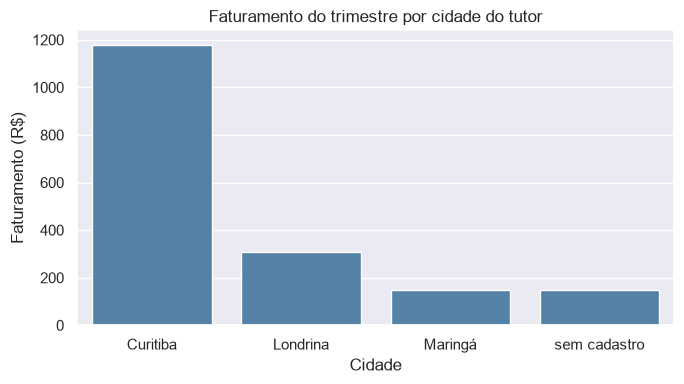

In [33]:
plt.figure(figsize=(7, 4))
sns.barplot(x=faturamento.index, y=faturamento["faturamento"], color="steelblue")
plt.title("Faturamento do trimestre por cidade do tutor")
plt.xlabel("Cidade")
plt.ylabel("Faturamento (R$)")
plt.tight_layout()
plt.show()

## Parte 8: Checklist antes e depois de juntar

Junções erradas **não dão erro**: elas só produzem números errados. Vale transformar os cuidados deste tutorial numa função que você reutiliza sempre.

| Antes | Depois |
|---|---|
| As chaves têm **o mesmo tipo**? | O número de linhas é o **esperado**? |
| A chave da tabela "um" é **única**? | Apareceram **nulos novos**? Quantas linhas ficaram sem par? |

### 🔍 Passo a passo
- A função recebe as duas tabelas e as chaves, faz um `left` com `indicator=True` e confere tudo com `assert`.
- Num `left` com relação "muitos para um", o resultado **precisa** ter o mesmo número de linhas da esquerda.

In [34]:
def juntar_com_checagem(esquerda, direita, chave_esq, chave_dir, **opcoes):
    # Antes de juntar
    assert esquerda[chave_esq].dtype == direita[chave_dir].dtype, \
        f"Tipos diferentes: {esquerda[chave_esq].dtype} x {direita[chave_dir].dtype}"
    assert direita[chave_dir].is_unique, f"A chave '{chave_dir}' se repete na tabela da direita"

    resultado = pd.merge(esquerda, direita, left_on=chave_esq, right_on=chave_dir,
                         how="left", indicator=True, **opcoes)

    # Depois de juntar
    assert len(resultado) == len(esquerda), "O número de linhas mudou!"
    sem_par = (resultado["_merge"] == "left_only").sum()
    print(f"Linhas: {len(esquerda)} antes, {len(resultado)} depois | sem par na direita: {sem_par}")
    return resultado.drop(columns="_merge")

resultado = juntar_com_checagem(animais, tutores, "tutor_id", "id", suffixes=("_animal", "_tutor"))

Linhas: 8 antes, 8 depois | sem par na direita: 1


E se tentarmos com a tabela de tutores duplicada? O checklist **para antes** de causar estrago:

In [35]:
try:
    juntar_com_checagem(animais, tutores_dup, "tutor_id", "id")
except AssertionError as erro:
    print("PAROU:", erro)

PAROU: A chave 'id' se repete na tabela da direita


## Parte 9: Exercícios

Tente fazer sozinho antes de olhar as dicas. Se precisar recomeçar, rode o notebook desde a Parte 1.

1. **Concat:** crie um quarto mês (`abr`) com 3 consultas e **sem** a coluna `valor`. Empilhe com os outros meses. Quantos `NaN` aparecem em `valor`? E com `join="inner"`, quais colunas sobram?
2. **Origem:** usando `keys`, descubra qual mês teve o maior faturamento. *(Dica: depois do `reset_index`, use `groupby("mes")`.)*
3. **How:** sem rodar o código, preveja quantas linhas terá `pd.merge(animais, tutores, left_on="tutor_id", right_on="id", how=...)` para cada um dos quatro `how`. Depois confira com `indicator=True`.
4. **Anti-join:** liste os tutores que **não tiveram nenhuma consulta** no trimestre. *(Dica: use a tabela `completo`.)*
5. **Chave composta:** acrescente à tabela `precos` a linha `("coelho", "vacina", 80.0)` e crie uma consulta de vacina para a Nina (`A06`). O `merge` da Parte 4.5 encontra o preço?
6. **Duplicados:** crie um `animais_dup` com o animal `A04` repetido e junte com `consultas` usando `validate="many_to_one"`. Qual mensagem aparece? Como você corrigiria a tabela?
7. **Join:** calcule o **gasto total por animal** (`groupby("animal_id")["valor"].sum()`) e junte com a tabela `animais` usando `set_index` e `join`. Quem gastou mais?
8. **Desafio:** crie a tabela "faturamento por espécie e por mês" juntando as três tabelas e usando `pivot_table` (Tutorial 4), com os meses nas colunas.

---

### Resumo do fluxo (cole na parede! 📌)

1. **Empilhar arquivos iguais**: `pd.concat(lista, ignore_index=True)` (use `keys` para guardar a origem)
2. **Antes de juntar**: conferir **tipo** e **espaços** das chaves (`dtype`, `str.strip`, `pd.to_numeric`) e se a chave é **única** (`is_unique`)
3. **Juntar por chave**: `pd.merge(..., on=...)` ou `left_on`/`right_on`, escolhendo o `how`
4. **Proteger**: `validate="many_to_one"` e `indicator=True`
5. **Quem ficou sem par**: filtrar `_merge == "left_only"` ou `"right_only"`
6. **Depois de juntar**: contar linhas e nulos novos
7. **Resumir**: `groupby` (Tutorial 4)

---

## Referências

- [1] Codd, E. F. (1970). A Relational Model of Data for Large Shared Data Banks. *Communications of the ACM*, 13(6), 377–387.
- [2] Wickham, H. (2014). Tidy Data. *Journal of Statistical Software*, 59(10), 1–23. https://doi.org/10.18637/jss.v059.i10
- [3] McKinney, W. (2022). *Python for Data Analysis* (3ª ed.), capítulo 8 (Data Wrangling: Join, Combine, and Reshape). O'Reilly. Gratuito em https://wesmckinney.com/book/
- [4] Date, C. J. (2003). *An Introduction to Database Systems* (8ª ed.). Addison-Wesley.
- [5] pandas development team. *Merge, join, concatenate and compare* (guia do usuário). https://pandas.pydata.org/docs/user_guide/merging.html

### 📖 Para continuar estudando (gratuitos)
- O capítulo 8 do livro de McKinney [3], escrito pelo criador do pandas.
- O guia oficial do pandas sobre junções [5], com diagramas de cada tipo de `merge`.
- *R for Data Science* (2ª ed.), capítulo "Joins": as ideias valem para Python também. https://r4ds.hadley.nz/joins